# 038 — Árvore individual e Bagging

Preparação central original. Fit apenas no treino de cada divisão. Seleção interna/CV dentro das 8.769 linhas; validação fixa de desenvolvimento com 2.193 linhas. Sem submissão automática.

Resultado real guardado; não foi iniciado novo treino.
Kaggle: por submeter
Configuração selecionada: {'params': {'kind': 'bagging', 'max_depth': 10}, 'label': 'kind=bagging, max_depth=10', 'cv_macro_f1': [0.4232940994965241, 0.41828718398331594, 0.411184978877038], 'cv_macro_f1_mean': 0.4175887541189593, 'cv_macro_f1_std': 0.006084698328667146, 'cv_accuracy_mean': 0.4439502793933174, 'cv_train_macro_f1_mean': 0.8483026729126267}
CSV: {'path': 'submissions/submission_038_novo_modelo.csv', 'differences': {'submission_001_regressao_logistica(1).csv': 1924, 'submission_002_regressao_logistica_regularizada.csv': 1727, 'submission_004_arvore_decisao.csv': 1961, 'submission_012_mlp_perda_ponderada.csv': 1852, 'submission_013_mlp_arquitetura.csv': 1852, 'submission_014_xgboost_mlp.csv': 1357, 'submission_015_mlp_learning_rate.csv': 1745, 'submission_028_ensemble_features_dominio.csv': 1368, 'submission_029_catboost.csv': 1198, 'submission_031_catboost_ponderacao_suave.csv': 1277, 'submission_

,parcela,Macro F1,accuracy
0,train,0.782307,0.768275
1,validation,0.447616,0.455996


,classe,escalão,F1,recall,support
0,0,15–17 anos,0.840909,0.902439,41
1,1,18–19 anos,0.360000,0.264706,34
2,2,20–24 anos,0.651163,0.700000,80
3,3,25–29 anos,0.262295,0.213333,75
4,4,30–34 anos,0.255034,0.211111,90
5,5,35–39 anos,0.326693,0.317829,129
6,6,40–44 anos,0.400000,0.482558,172
7,7,45–49 anos,0.352239,0.341040,173
8,8,50–54 anos,0.570652,0.580110,181
9,9,55–59 anos,0.600462,0.640394,203


,params,label,cv_macro_f1,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean,cv_train_macro_f1_mean
0,"{'kind': 'tree', 'max_depth': 5}","kind=tree, max_depth=5","[0.37395255532123495, 0.3258334760664924, 0.32...",0.341156,0.028423,0.394116,0.363684
1,"{'kind': 'bagging', 'max_depth': 5}","kind=bagging, max_depth=5","[0.3601000553449956, 0.3593306843677928, 0.352...",0.357386,0.004053,0.409853,0.395139
2,"{'kind': 'bagging', 'max_depth': 10}","kind=bagging, max_depth=10","[0.4232940994965241, 0.41828718398331594, 0.41...",0.417589,0.006085,0.443950,0.848303


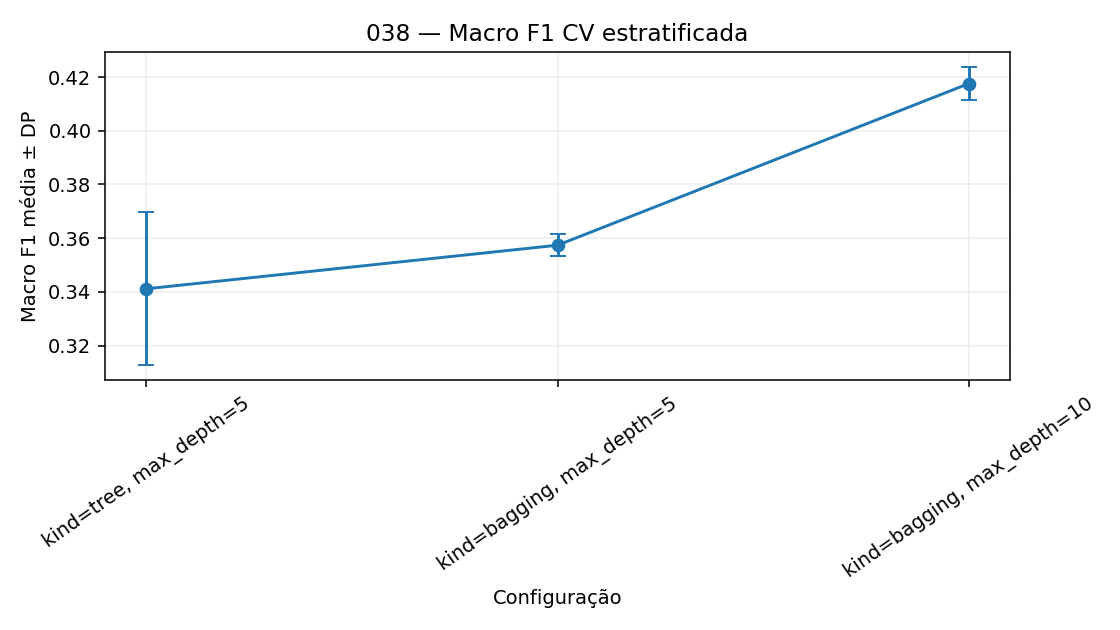

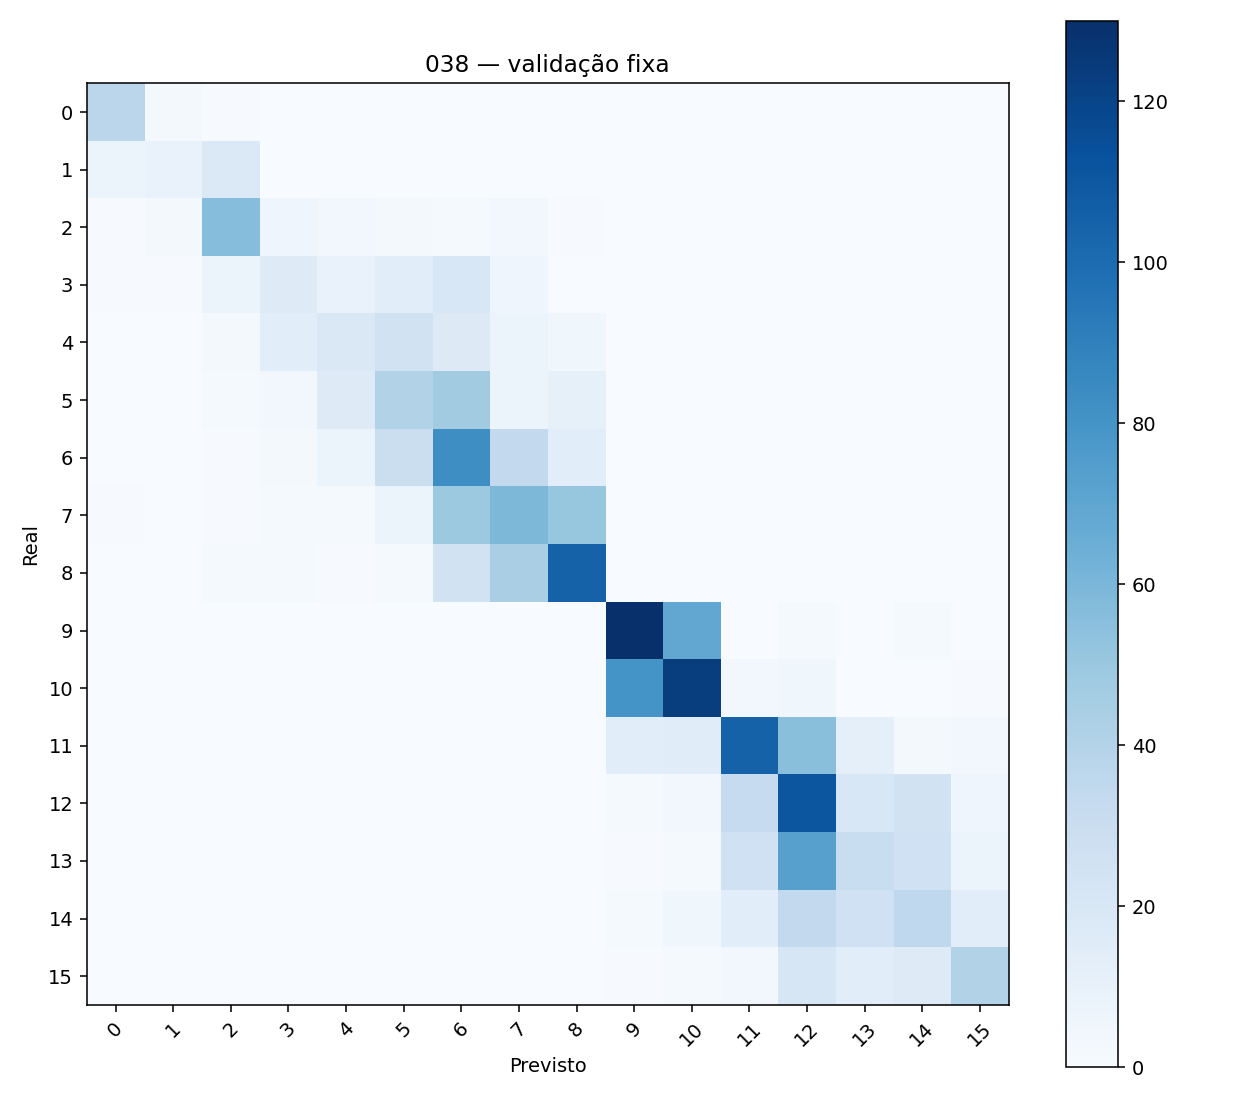

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'src/ver_resultados.py').is_file())
sys.path.insert(0, str(root))
from src.ver_resultados import carregar_resultado
result = carregar_resultado('038')
print('Resultado real guardado; não foi iniciado novo treino.')
print('Kaggle: por submeter')
selected = result.get('selected_internally', result.get('selected'))
if isinstance(selected, dict): selected = {k:v for k,v in selected.items() if k not in ['history', 'ae', 'folds']}
print('Configuração selecionada:', selected)
metrics = result.get('fixed_metrics', result.get('metrics', {}))
if metrics:
    display(pd.DataFrame([{'parcela':k, 'Macro F1':m['macro_f1'], 'accuracy':m['accuracy']} for k,m in metrics.items() if isinstance(m,dict) and 'macro_f1' in m]))
    if 'validation' in metrics:
        detail = metrics['validation'].get('per_class', metrics['validation'].get('classification_report', {}))
        if detail: display(pd.DataFrame(detail))
rows = result.get('candidates', result.get('results', []))
if rows:
    display(pd.DataFrame([{k:v for k,v in r.items() if k not in ['history','ae','folds','age_profile_posthoc','sizes']} for r in rows]))
images = list((root/'reports').glob('experiencia_038_*.png')) + list((root/'reports').glob('038*.png'))
for p in sorted(set(images)): display(Image(filename=str(p)))
print('CSV:', result.get('submission'))
print('Notas:', result.get('note', ''))


## Conclusão e Decisão
- Data: 17/11
- Pontuação Kaggle: 0.43
- Macro F1 de desenvolvimento: **0.4476**; accuracy: **0.4560**. Abaixo da referência histórica 025 (0,4615); não demonstra uma melhoria global.
- Conclusão: Apesar do resultado local de 0,4476, não trouxe melhoria face aos melhores modelos.
- Melhorias: Ajustar min_samples_leaf e max_features numa pesquisa curta com os mesmos folds.